In [1]:
# !pip innstall yfinance pandas numpy matplotlib seaborn plotly mplfinance statsmodels prophet
# !pip istall pmdarima scikit-learn holidays xgboost joblib

In [2]:
# ============================================================
# ANÁLISE E AVALIAÇÃO DE AÇÕES
# ============================================================

import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import warnings

from IPython.display import display, Markdown
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import mplfinance as mpf

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-darkgrid')

# ============================================================
# IMPORT DAS FUNÇÕES DO ARQUIVO funcoes_pemporais.py
# ============================================================
sys.path.insert(0, os.path.abspath('../funcoes'))
import funcoes_temporais as ft


In [3]:
# ============================================================
# AQUISIÇÃO DE DADOS (yfinance)
# ============================================================

TICKER = 'PETR4.SA'          # Petrobras na B3 (sufixo .SA)
INICIO = '1900-01-01'
FIM    = '2024-12-31'

#df = yf.download(TICKER, start=INICIO, end=FIM, auto_adjust=True)
df = yf.download(TICKER, start=INICIO, auto_adjust=True)
df.columns = [c[0] if isinstance(c, tuple) else c for c in df.columns]

# Indicadores uteis para a análise financeira
# df['Retorno']    = df['Close'].pct_change()
# df['LogRetorno'] = np.log(df['Close'] / df['Close'].shift(1))
# df['SMA_20']     = df['Close'].rolling(20).mean()
# df['SMA_50']     = df['Close'].rolling(50).mean()
# df['SMA_200']    = df['Close'].rolling(200).mean()
# df['Vol_20d']    = df['Retorno'].rolling(20).std() * np.sqrt(252) * 100
# Para essa aula nos limitaremos a análise temporal

[*********************100%***********************]  1 of 1 completed


In [4]:
# ============================================================
# ANÁLISE EXPLORATÓRIA (EDA)
# ============================================================
# Informações gerais
print("=" * 60)
print(f"INFORMAÇÕES DO DATAFRAME")
print("=" * 60)
df.info()

INFORMAÇÕES DO DATAFRAME
<class 'pandas.DataFrame'>
DatetimeIndex: 6727 entries, 2000-01-03 to 2026-10-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   6727 non-null   float64
 1   High    6727 non-null   float64
 2   Low     6727 non-null   float64
 3   Open    6727 non-null   float64
 4   Volume  6727 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 315.3 KB


In [5]:
# Primeiros  e últimos registros
n=5
print("=" * 60)
print(f"PRIMEIROS {n} REGISTROS")
print("=" * 60)
display(df.head(n))

print("=" * 60)
print(f"ÚLTIMOS {n} REGISTROS")
print("=" * 60)
display(df.tail(n))

PRIMEIROS 5 REGISTROS


,Close,High,Low,Open,Volume
Date,,,,,
2000-01-03,1.054027,1.054027,1.054027,1.054027,35389440000
2000-01-04,0.995719,0.995719,0.995719,0.995719,28861440000
2000-01-05,0.985672,0.985672,0.985672,0.985672,43033600000
2000-01-06,0.982263,0.982263,0.982263,0.982263,34055680000
2000-01-07,0.986748,0.986748,0.986748,0.986748,20912640000


ÚLTIMOS 5 REGISTROS


,Close,High,Low,Open,Volume
Date,,,,,
2026-10-14,58.110001,58.110001,56.740002,56.880001,42367600
2026-10-15,57.360001,58.090000,57.090000,57.599998,37576500
2026-10-16,59.680000,59.680000,57.529999,57.660000,56657800
2026-10-19,58.000000,59.299999,57.950001,59.299999,35174800
2026-10-20,58.209999,59.099998,56.910000,58.820000,42452200


In [6]:
# Vamos trabalha apenas com o valor de fechamento
df_original = df.copy()
df = df[['Close']]

In [7]:
# Verificação completa da série (lacunas, duplicatas, nulos...)
resultado_eda = ft.verificar_serie(df,frequencia='U')
display(Markdown(resultado_eda['mensagem']) )


## Resumo da EDA

### Qualidade dos Dados
- ✅ É uma Série Temporal
- ✅ Frequência: `U (dias úteis)`
- ✅ 6727 observações (03/01/2000 a 20/10/2026)

- ❌ Esta série tem 128 lacunas reais no período ['25/01/2005 00:00', '07/02/2005 00:00', '08/02/2005 00:00', '26/05/2005 00:00', '30/12/2005 00:00', '29/12/2006 00:00', '25/01/2007 00:00', '19/02/2007 00:00', '20/02/2007 00:00', '07/06/2007 00:00']...

- ⚠️ Esta série tem 43 marcações indevidas (fora do conjunto válido para a frequência U): ['21/04/2000 00:00', '01/05/2000 00:00', '07/09/2000 00:00', '12/10/2000 00:00', '02/11/2000 00:00', '15/11/2000 00:00', '25/12/2000 00:00', '01/01/2001 00:00', '13/04/2001 00:00', '01/05/2001 00:00']...

- ✅ 0 valores nulos

- ✅ 0 períodos duplicados

- ✅ 0 períodos com marcações múltiplas

- ✅ 0 valores negativos

- ✅ 0 valores zerados


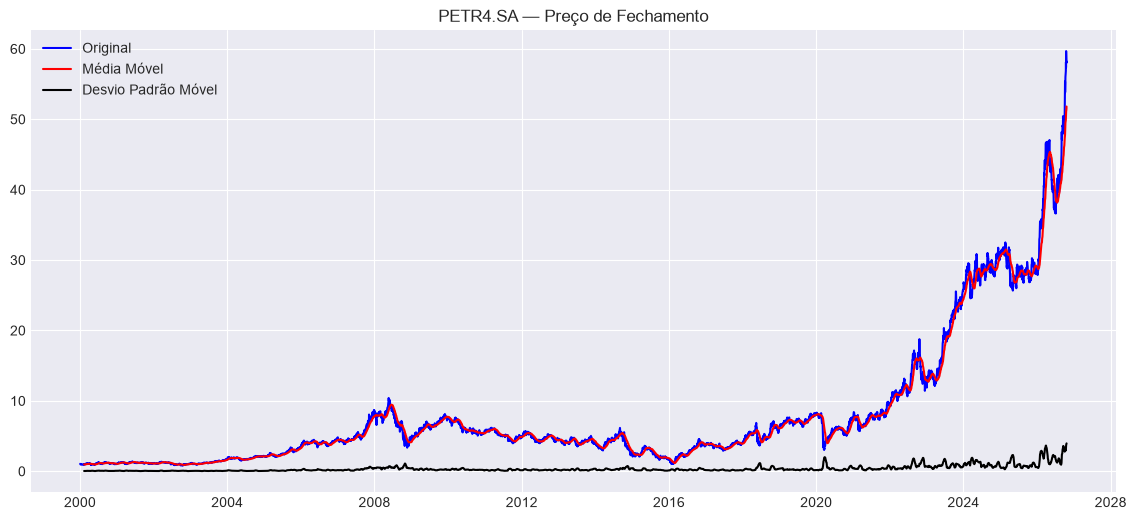


TESTE ADF — Dickey-Fuller Aumentado
H0: a série tem raiz unitária (NÃO estacionária)
Estatística do Teste               3.750600
Valor-p                            1.000000
Número de Lags Consideradas       33.000000
Número de Observações Usadas    6693.000000
Valor Crítico (1%)                -3.431327
Valor Crítico (5%)                -2.861972
Valor Crítico (10%)               -2.567000
dtype: float64

TESTE KPSS — nível (regression="c")
H0: a série é estacionária em nível
Estatística do Teste      6.690386
Valor-p                   0.010000
Número de Lags Usadas    51.000000
Valor Crítico (10%)       0.347000
Valor Crítico (5%)        0.463000
Valor Crítico (2.5%)      0.574000
Valor Crítico (1%)        0.739000
dtype: float64

CONCLUSÃO COMBINADA (ADF + KPSS)
ADF        → p = 1.0000 → não estacionária
KPSS nível → p = 0.0100 → não estacionária

Conclusão: NÃO ESTACIONÁRIA
Ambos os testes concordam: a série NÃO é estacionária.
ADF não rejeitou a raiz unitária (p > 0.05) e KPSS rej

In [8]:
# ============================================================
# AVALIAÇÃO DA ESTACIONARIEDADE
# ============================================================
estacionaria = ft.testa_estacionaridade(df['Close'].dropna(), window=30,
                             title=f'{TICKER} — Preço de Fechamento')

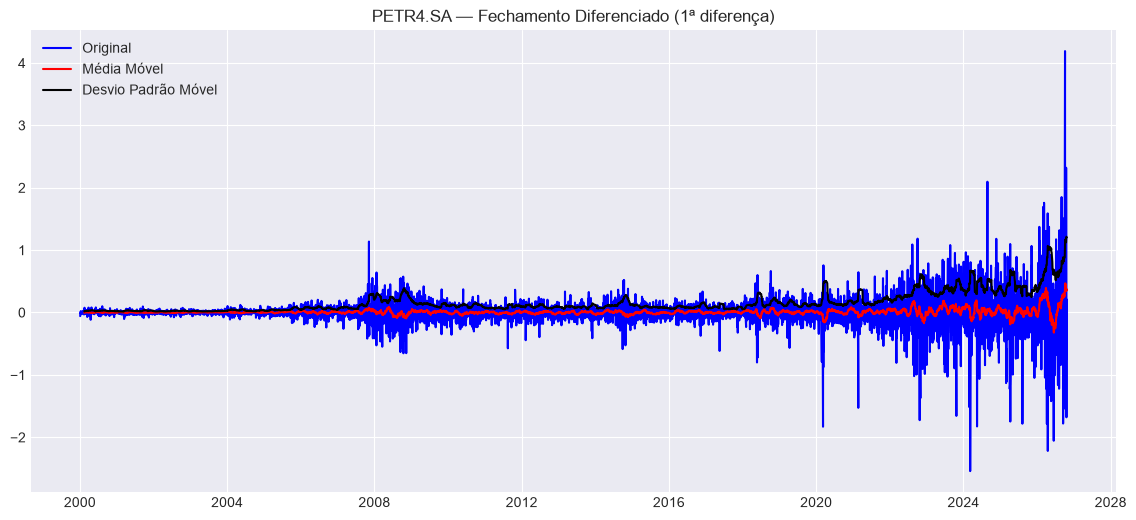


TESTE ADF — Dickey-Fuller Aumentado
H0: a série tem raiz unitária (NÃO estacionária)
Estatística do Teste           -9.698877e+00
Valor-p                         1.085638e-16
Número de Lags Consideradas     3.500000e+01
Número de Observações Usadas    6.690000e+03
Valor Crítico (1%)             -3.431328e+00
Valor Crítico (5%)             -2.861972e+00
Valor Crítico (10%)            -2.567000e+00
dtype: float64

TESTE KPSS — nível (regression="c")
H0: a série é estacionária em nível
Estatística do Teste      1.1745
Valor-p                   0.0100
Número de Lags Usadas    22.0000
Valor Crítico (10%)       0.3470
Valor Crítico (5%)        0.4630
Valor Crítico (2.5%)      0.5740
Valor Crítico (1%)        0.7390
dtype: float64

⚠️ CONFLITO DETECTADO — ADF estacionária + KPSS não estacionária
Rodando KPSS com regression="ct" (estacionariedade em tendência)...
Estatística do Teste      0.294954
Valor-p                   0.010000
Número de Lags Usadas    21.000000
Valor Crítico (10%)       

In [9]:
# 1ª diferença do fechamento (remove a tendência)
df['Close_diff'] = df['Close'].diff()

# Re-testa a estacionaridade da série diferenciada
ft.testa_estacionaridade(
    df['Close_diff'].dropna(),
    window=30,
    title=f'{TICKER} — Fechamento Diferenciado (1ª diferença)'
)
# Série a analisar (preço de fechamento, sem nulos)
serie = df['Close_diff'].dropna()
n = len(serie)

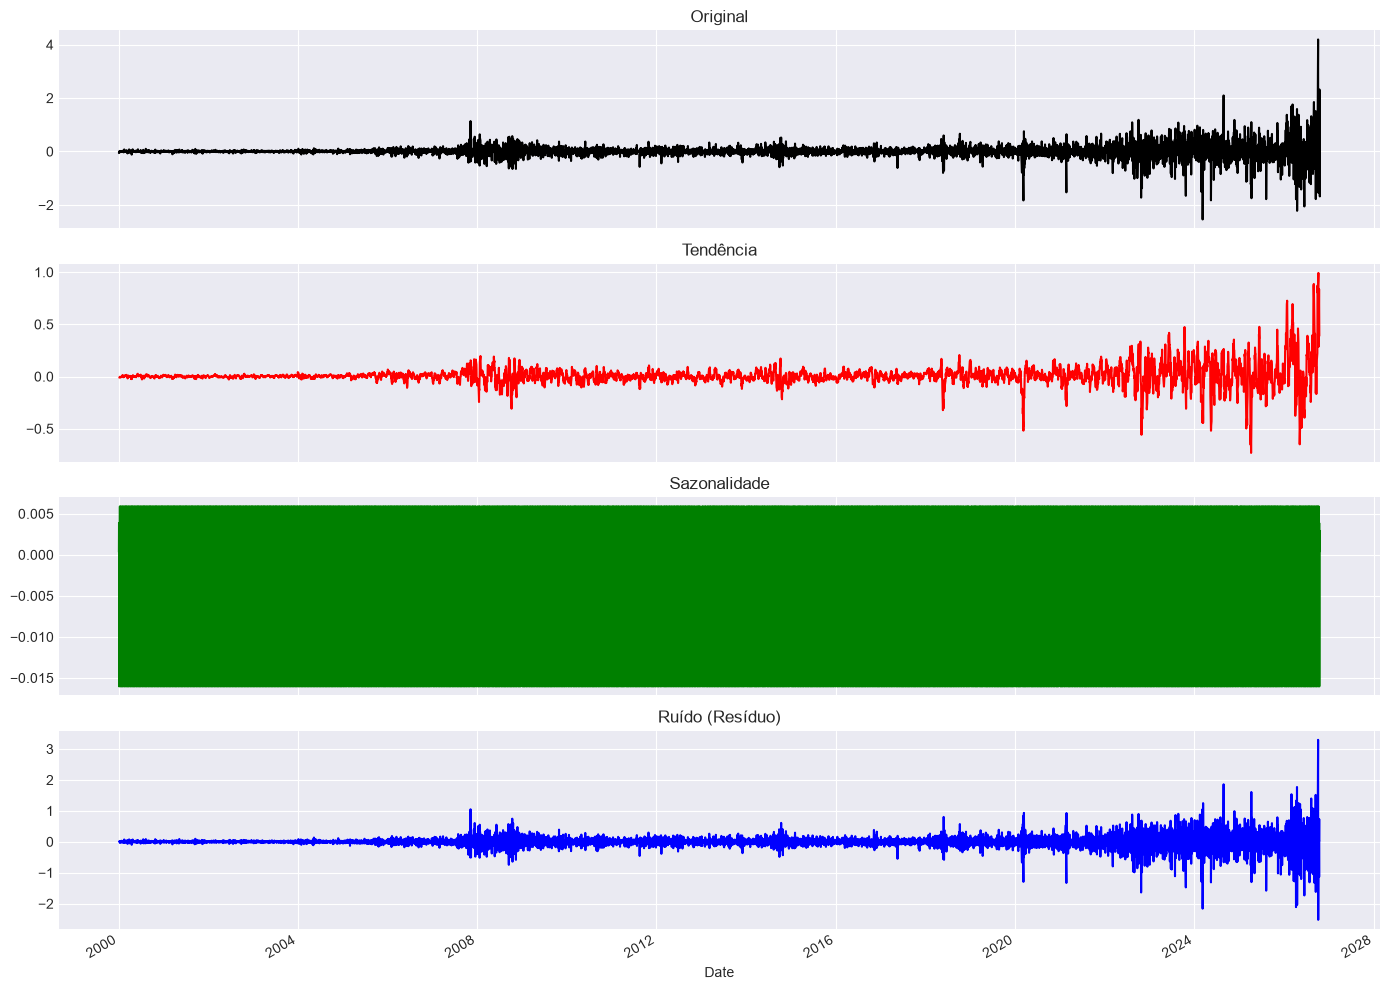


    
## Análise da Decomposição
### Componentes
- ✅ Modelo: additive | Período sazonal: 7
- 📈 Tendência: força 0.16 (FRACA)
- 🔁 Sazonalidade: força 0.00 (FRACA)
- 🌫️ Ruído: média -0.0001, desvio padrão 0.2167
- ⚠️ Resíduos com autocorrelação significativa (Ljung-Box p=0.0000) — há padrão não capturado
- 🔍 145 outliers no resíduo (|z| > 3)


In [10]:
# ============================================================
# ANÁLISE DA DECOMPOSIÇÃO
# ============================================================
# Decomposição do fechamento (período 7 = semanal)
analise = ft.decompor_serie(serie, period=7)
display(Markdown(analise['mensagem']) )

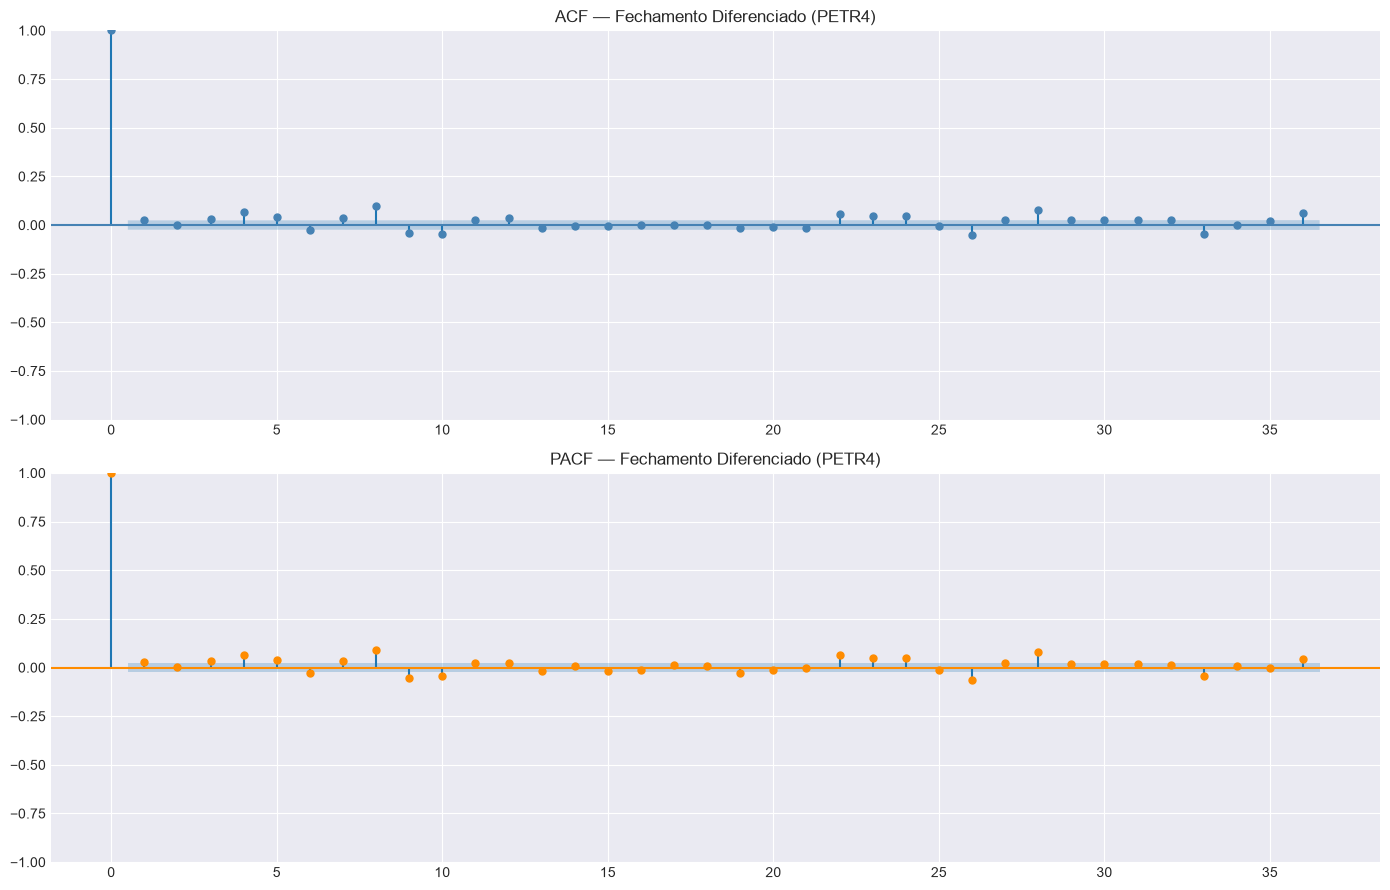


## 📊 Avaliação do ACF/PACF — Fechamento Diferenciado

### Interpretação Automática
- **Lags ACF significativos:** [1, 3, 4, 5, 7, 8, 9, 10, 11, 12]
- **Lags PACF significativos:** [1, 3, 4, 5, 6, 7, 8, 9, 10, 19]
- **Corte ACF:** 1 | **Corte PACF:** 1
- **ACF decai (tail-off):** True | **PACF decai:** True
- **Lags sazonais ACF:** [12, 24, 36]
- **Lags sazonais PACF:** [24, 36]

### Tabela de Lags Significativos
| Lag | ACF | PACF |
|---|---|---|
| 1 | +0.028 ✅ | +0.028 ✅ |
| 2 | +0.001 — | +0.000 — |
| 3 | +0.031 ✅ | +0.031 ✅ |
| 4 | +0.068 ✅ | +0.067 ✅ |
| 5 | +0.040 ✅ | +0.036 ✅ |
| 6 | -0.023 — | -0.026 ✅ |
| 7 | +0.038 ✅ | +0.036 ✅ |
| 8 | +0.100 ✅ | +0.092 ✅ |
| 9 | -0.043 ✅ | -0.052 ✅ |
| 10 | -0.045 ✅ | -0.044 ✅ |
| **12** (sazonal) | +0.036 ✅ | +0.023 — |
| **24** (sazonal) | +0.045 ✅ | +0.047 ✅ |
| **36** (sazonal) | +0.062 ✅ | +0.042 ✅ |


In [11]:
# ============================================================
# AVALIAÇÃO DO ACF/PACF (AUTOCORRELAÇÃO)
# ============================================================
# Série estacionária (fechamento diferenciado)
serie = df['Close_diff'].dropna()
if serie.index.tz is not None:
    serie.index = serie.index.tz_localize(None)
n = len(serie)
nlags = min(36, n // 2 - 1)

# ===== 5.1 GRÁFICOS ACF e PACF =====
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(serie, lags=nlags, ax=axes[0],
         title='ACF — Fechamento Diferenciado (PETR4)',
         color='steelblue', alpha=0.05)

plot_pacf(serie, lags=nlags, ax=axes[1], method='ywm',
          title='PACF — Fechamento Diferenciado (PETR4)',
          color='darkorange', alpha=0.05)

plt.tight_layout()
plt.show()

# ===== 5.2 CÁLCULO ACF/PACF =====
acf_vals  = acf(serie, nlags=nlags)
pacf_vals = pacf(serie, nlags=nlags, method='ywm')
conf_int  = 1.96 / np.sqrt(n)

# ===== 5.3 INTERPRETAÇÃO AUTOMÁTICA =====
interp = ft.interpretar_acf_pacf(acf_vals, pacf_vals, conf_int, 'Fechamento Diferenciado')

# ===== 5.4 SAÍDA EM MARKDOWN =====
mensagem_md = f"""
## 📊 Avaliação do ACF/PACF — Fechamento Diferenciado

### Interpretação Automática
- **Lags ACF significativos:** {interp['lags_acf_sig']}
- **Lags PACF significativos:** {interp['lags_pacf_sig']}
- **Corte ACF:** {interp['corte_acf']} | **Corte PACF:** {interp['corte_pacf']}
- **ACF decai (tail-off):** {interp['acf_tail_off']} | **PACF decai:** {interp['pacf_tail_off']}
- **Lags sazonais ACF:** {interp['lags_sazonais_acf']}
- **Lags sazonais PACF:** {interp['lags_sazonais_pacf']}

### Tabela de Lags Significativos
| Lag | ACF | PACF |
|---|---|---|
{ft.tabela_lags_significativos(acf_vals, pacf_vals, conf_int)}
"""
display(Markdown(mensagem_md))

In [12]:
# ============================================================
# DIVISÃO TREINO/TESTE (temporal — nunca aleatória)
# ============================================================

n = len(serie)
corte = int(n * 0.8)
treino = serie.iloc[:corte]
teste  = serie.iloc[corte:]
# treino = treino.asfreq('B')
# teste  = teste.asfreq('B')  
print(f'Treino: {treino.index.min().date()} a {treino.index.max().date()} ({len(treino)} obs)')
print(f'Teste : {teste.index.min().date()} a {teste.index.max().date()} ({len(teste)} obs)')

Treino: 2000-01-04 a 2021-05-28 (5380 obs)
Teste : 2021-05-31 a 2026-10-20 (1346 obs)


In [13]:
# ============================================================
# GERANDO OS MODELOS
# ============================================================
passos_teste = len(teste)
print("\n[*] Iniciando treinamento e avaliação de modelos (isso pode levar alguns segundos)...")

previsoes = {
    'SARIMA': ft.treinar_sarima(treino.reset_index(drop=True), passos_teste),
    'Auto-ARIMA': ft.treinar_autoarima(treino.reset_index(drop=True), passos_teste),
    'Prophet': ft.treinar_prophet(treino, passos_teste),
    'Holt-Winters': ft.treinar_holt_winters(treino.reset_index(drop=True), passos_teste),
    'Theta': ft.treinar_theta(treino.reset_index(drop=True), passos_teste),
    'XGBoost': ft.treinar_xgboost(treino, passos_teste)
}


[*] Iniciando treinamento e avaliação de modelos (isso pode levar alguns segundos)...


21:26:11 - cmdstanpy - INFO - Chain [1] start processing
21:26:11 - cmdstanpy - INFO - Chain [1] done processing


In [14]:
# ============================================================
# REVERSÃO PARA VALORES REAIS (Integração da Diferença)
# ============================================================

# 1. Pegamos a série original de fechamento
precos_reais = df_original['Close'].dropna()

if precos_reais.index.tz is not None:
    precos_reais.index = precos_reais.index.tz_localize(None)

# O SEGREDO: Cortar usando exatamente o mesmo índice (datas) da série diferenciada!
# Isso garante que as shapes sejam 100% idênticas (ex: 1345 e 1345)
preco_treino = precos_reais.loc[treino.index]
preco_teste  = precos_reais.loc[teste.index]

# Pegamos o ÚLTIMO preço conhecido antes do futuro começar
ultimo_preco_conhecido = preco_treino.iloc[-1]

# 2. Revertendo a diferença (Soma Cumulativa)
previsoes_em_reais = {}
resultados_metricas_reais = {}

for nome, pred_diff in previsoes.items():
    # A mágica: Último Preço + Soma Cumulativa das diferenças previstas
    pred_preco_real = ultimo_preco_conhecido + np.cumsum(pred_diff)
    previsoes_em_reais[nome] = pred_preco_real

    # Calcula a métrica usando o Preço Real vs Preço Previsto Real
    resultados_metricas_reais[nome] = ft.calcular_metricas(preco_teste.values, pred_preco_real)

# Exibe a tabela de métricas com os valores REAIS (RMSE agora em R$)
df_resultados_reais = pd.DataFrame(resultados_metricas_reais).T
print("\n=== COMPARAÇÃO DOS MODELOS (VALORES EM REAIS) ===")
print(df_resultados_reais.sort_values(by='RMSE'))


=== COMPARAÇÃO DOS MODELOS (VALORES EM REAIS) ===
                    MAE       RMSE       MAPE      sMAPE
Theta         11.340150  14.177332  40.209185  53.601034
Prophet       12.286725  15.108378  44.316056  60.499439
XGBoost       13.032263  16.045336  46.912173  65.489289
Holt-Winters  14.921966  18.217305  54.103818  80.040171
SARIMA        15.127954  18.455047  54.894275  81.740556
Auto-ARIMA    15.931526  19.369735  58.019313  88.653486


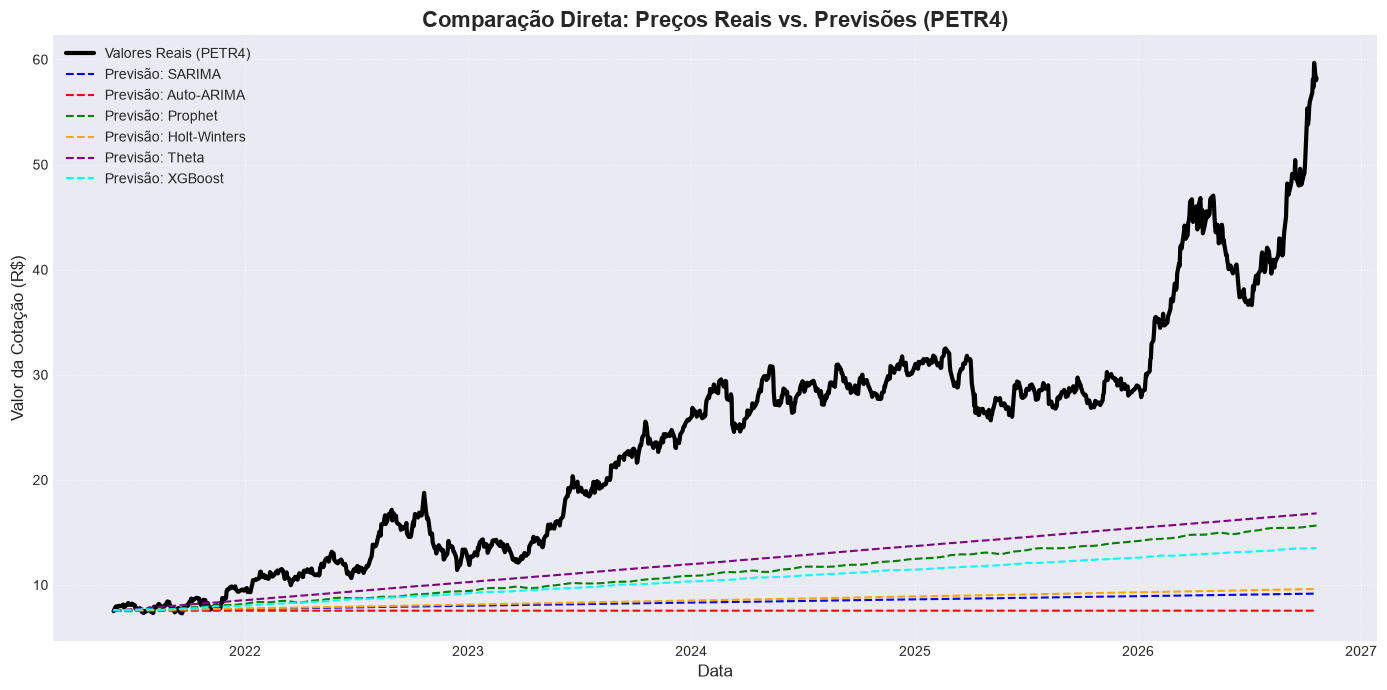

In [15]:
import matplotlib.pyplot as plt

# ============================================================
# 5. GRÁFICO DE LINHAS: PREÇOS REAIS VS PREVISÕES REAIS
# ============================================================

# Cria a figura com um tamanho bom para visualização
plt.figure(figsize=(14, 7))

# 1. Plotando os valores reais (O Gabarito)
# Usamos o 'preco_teste' que tem o preço exato da Petrobras naqueles dias
plt.plot(preco_teste.index, preco_teste.values, label='Valores Reais (PETR4)', color='black', linewidth=3)

# 2. Plotando as previsões revertidas de cada modelo
cores = ['blue', 'red', 'green', 'orange', 'purple', 'cyan']

# Iteramos sobre as previsões já convertidas para Reais (R$)
for (nome, pred_real), cor in zip(previsoes_em_reais.items(), cores):
    plt.plot(preco_teste.index, pred_real, label=f'Previsão: {nome}', color=cor, linestyle='--', linewidth=1.5)

# 3. Estilização do Gráfico
plt.title('Comparação Direta: Preços Reais vs. Previsões (PETR4)', fontsize=16, fontweight='bold')
plt.xlabel('Data', fontsize=12)
plt.ylabel('Valor da Cotação (R$)', fontsize=12)

# Adiciona a legenda na melhor posição possível para não tampar as linhas
plt.legend(loc='best', fontsize=10) 

# Adiciona uma grade de fundo para facilitar a leitura de preços e datas
plt.grid(True, linestyle=':', alpha=0.7)

# Ajusta as margens
plt.tight_layout()

# Exibe o gráfico na tela!
plt.show()

In [16]:
# ============================================================
# ESCOLHA DO MELHOR MODELO
# ============================================================
# Usamos a nova variável df_resultados_reais
melhor_modelo_nome = df_resultados_reais['RMSE'].idxmin()

print(f"\n[+] Melhor Modelo Vencedor: {melhor_modelo_nome} (Baseado no menor RMSE)")


[+] Melhor Modelo Vencedor: Theta (Baseado no menor RMSE)


In [17]:
print("[*] Preparando modelo para PRODUÇÃO (treinando com 100% dos dados)...")

# A série completa de treino (a diferenciada)
serie_completa = serie.asfreq('B').ffill().bfill()

# ============================================================
# GERANDO PREVISÃO FUTURA (PRODUÇÃO)
# ============================================================
# Executa a produção (gera as diferenças previstas para os próximos 5 dias)
arquivo_salvo, prev_futura_diff = ft.gerar_modelo_producao(serie_completa, melhor_modelo_nome)

# Pegamos o ÚLTIMO preço que a Petrobras fechou hoje (para somar a diferença em cima dele)
ultimo_preco_hoje = precos_reais.iloc[-1]

# Mágica final: Converte as diferenças dos próximos 5 dias para o Preço Real!
prev_futura_real = ultimo_preco_hoje + np.cumsum(prev_futura_diff)

# Imprimindo o resultado final!
print(f"\n[!] MODELO SALVO COM SUCESSO: {arquivo_salvo}")
print(f"[!] PREVISÃO DA COTAÇÃO (R$) PARA OS PRÓXIMOS 5 DIAS ÚTEIS:")

datas_futuras = pd.bdate_range(start=serie_completa.index.max() + pd.Timedelta(days=1), periods=5)

for data, valor in zip(datas_futuras, prev_futura_real):
    print(f"    -> {data.date()}: R$ {valor:.2f}")

[*] Preparando modelo para PRODUÇÃO (treinando com 100% dos dados)...

[!] MODELO SALVO COM SUCESSO: modelo_theta_petr4.pkl
[!] PREVISÃO DA COTAÇÃO (R$) PARA OS PRÓXIMOS 5 DIAS ÚTEIS:
    -> 2026-10-21: R$ 58.35
    -> 2026-10-22: R$ 58.48
    -> 2026-10-23: R$ 58.60
    -> 2026-10-26: R$ 58.74
    -> 2026-10-27: R$ 58.88


In [18]:
df

,Close,Close_diff
Date,,
2000-01-03,1.054027,NaN
2000-01-04,0.995719,-0.058308
2000-01-05,0.985672,-0.010047
2000-01-06,0.982263,-0.003409
2000-01-07,0.986748,0.004485
...,...,...
2026-10-14,58.110001,1.260002
2026-10-15,57.360001,-0.750000
2026-10-16,59.680000,2.320000


In [22]:
previsoes['Prophet']

array([-0.00557747, -0.00025008,  0.0012186 , ...,  0.0050005 ,
        0.0037976 ,  0.00487364], shape=(1346,))